# 02 – Erster Blick: AIFS Single (ECMWF, KI-Modell)

Einzelvorhersagen des KI-Modells AIFS, Start täglich 00 UTC, am nächsten Gitterpunkt zur Station (53,75° N, 10,0° E,
etwa 13 km entfernt). Temperatur in °C, Niederschlag als **Rate** in kg m⁻² s⁻¹ (das ist dasselbe wie mm pro Sekunde).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/aifs_single_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "valid_time"]
)

df.head()

,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude
0,2024-04-01,0.0,2024-04-01 00:00:00,6.78125,NaN,53.75,10.0
1,2024-04-01,6.0,2024-04-01 06:00:00,6.09375,0.000003,53.75,10.0
2,2024-04-01,12.0,2024-04-01 12:00:00,8.62500,0.000216,53.75,10.0
3,2024-04-01,18.0,2024-04-01 18:00:00,8.43750,0.000387,53.75,10.0
4,2024-04-01,24.0,2024-04-02 00:00:00,8.06250,0.000106,53.75,10.0


In [2]:
print(f"Anzahl Datensätze: {len(df):,}")

print("Vorhersagen ab:",
      df["init_time"].min())

print("Vorhersagen bis:",
      df["init_time"].max())

Anzahl Datensätze: 58,621
Vorhersagen ab: 2024-04-01 00:00:00
Vorhersagen bis: 2026-11-17 00:00:00


## Welche Lead Times gibt es?

In [3]:
sorted(df["lead_time_h"].unique())

[np.float64(0.0),
 np.float64(6.0),
 np.float64(12.0),
 np.float64(18.0),
 np.float64(24.0),
 np.float64(30.0),
 np.float64(36.0),
 np.float64(42.0),
 np.float64(48.0),
 np.float64(54.0),
 np.float64(60.0),
 np.float64(66.0),
 np.float64(72.0),
 np.float64(78.0),
 np.float64(84.0),
 np.float64(90.0),
 np.float64(96.0),
 np.float64(102.0),
 np.float64(108.0),
 np.float64(114.0),
 np.float64(120.0),
 np.float64(126.0),
 np.float64(132.0),
 np.float64(138.0),
 np.float64(144.0),
 np.float64(150.0),
 np.float64(156.0),
 np.float64(162.0),
 np.float64(168.0),
 np.float64(174.0),
 np.float64(180.0),
 np.float64(186.0),
 np.float64(192.0),
 np.float64(198.0),
 np.float64(204.0),
 np.float64(210.0),
 np.float64(216.0),
 np.float64(222.0),
 np.float64(228.0),
 np.float64(234.0),
 np.float64(240.0),
 np.float64(246.0),
 np.float64(252.0),
 np.float64(258.0),
 np.float64(264.0),
 np.float64(270.0),
 np.float64(276.0),
 np.float64(282.0),
 np.float64(288.0),
 np.float64(294.0),
 np.float64(300.0),

In [4]:
print("Anzahl Lead Times:",
      df["lead_time_h"].nunique())

Anzahl Lead Times: 61


61 Lead Times: 0 bis 360 h (15 Tage) in 6-h-Schritten. Für den Vergleich nutzen wir nur +6 h bis +240 h, weil
GraphCast nur 10 Tage weit rechnet.

## Haben alle Vorhersagen die gleiche Anzahl an Lead Times?

In [5]:
lead_counts = (
    df.groupby("init_time")
      .size()
)

In [6]:
lead_counts.describe()

count    961.0
mean      61.0
std        0.0
min       61.0
25%       61.0
50%       61.0
75%       61.0
max       61.0
dtype: float64

In [7]:
lead_counts[lead_counts != 61]

Series([], dtype: int64)

## Fehlende Werte

In [8]:
missing = df.isna().sum()

pd.DataFrame({
    "Missing": missing,
    "Percent": missing / len(df) * 100
})

,Missing,Percent
init_time,0,0.000000
lead_time_h,0,0.000000
valid_time,0,0.000000
temperature_2m,0,0.000000
precipitation_surface,961,1.639344
latitude,0,0.000000
longitude,0,0.000000


Nur der Niederschlag fehlt, und zwar genau bei Lead Time 0 (961 Läufe = 961 fehlende Werte). Zum Startzeitpunkt gibt
es noch kein Zeitintervall, in dem Niederschlag gefallen sein könnte. Das ist also kein echtes Datenproblem.

## Fehlende Vorhersagen

In [9]:
daily_forecasts = (
    df.groupby(df["init_time"].dt.date)
      .size()
)

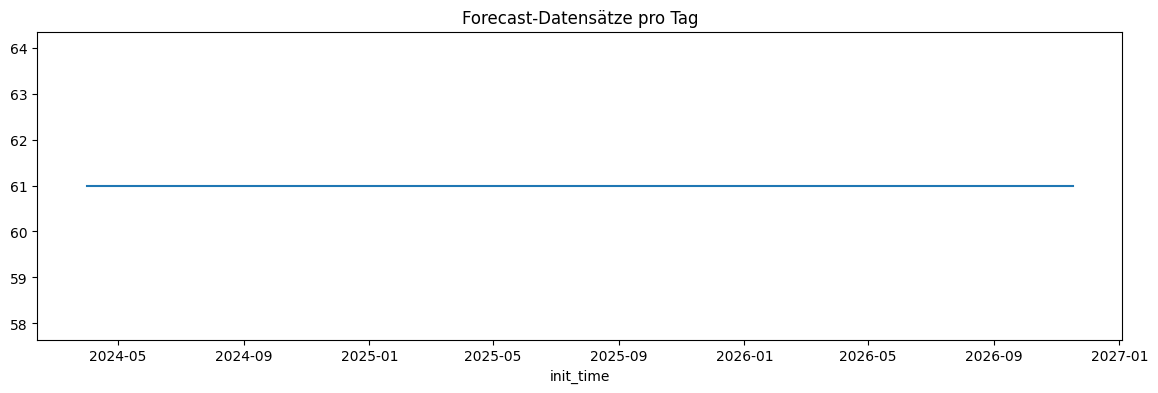

In [10]:
plt.figure(figsize=(14,4))

daily_forecasts.plot()

plt.title("Forecast-Datensätze pro Tag")
plt.show()

Jeder Tag hat genau einen Lauf mit 61 Zeilen; es fehlt kein Start.

## Temperaturverteilung

In [11]:
outliers = df[
    (df["temperature_2m"] < -50) |
    (df["temperature_2m"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude


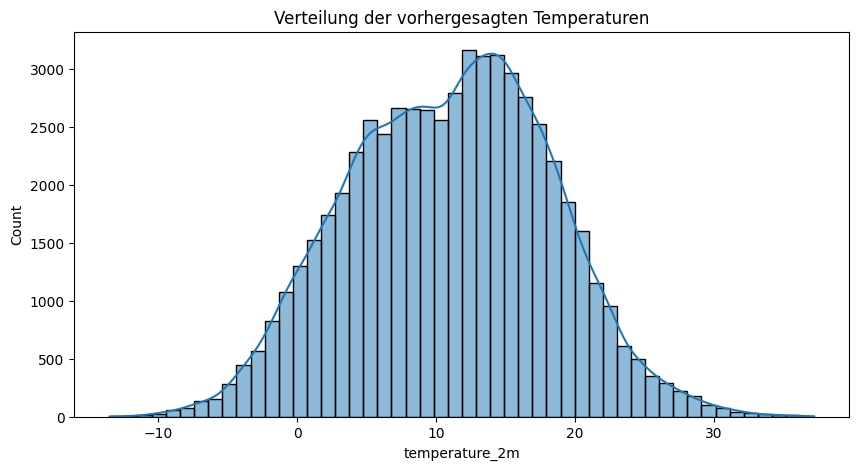

In [12]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.title("Verteilung der vorhergesagten Temperaturen")
plt.show()

## Mittlere Temperatur nach Lead Time

In [13]:
mean_temp_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .mean()
)

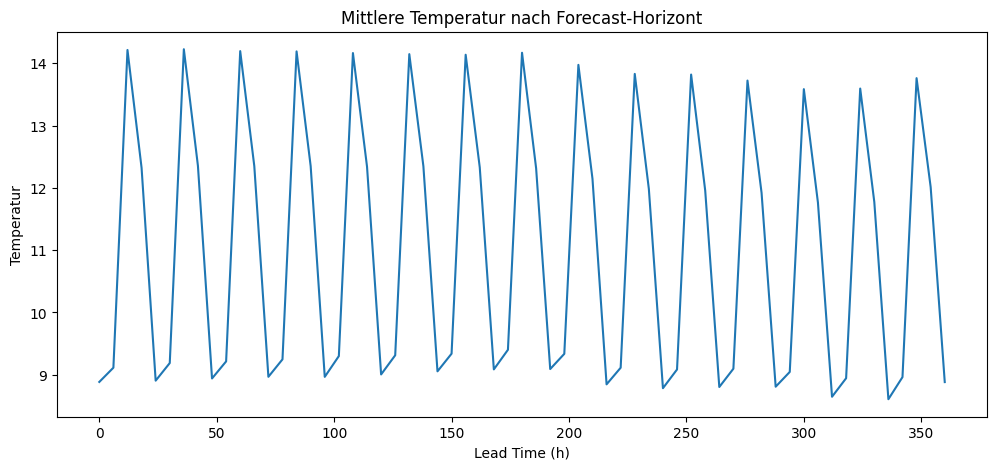

In [14]:
plt.figure(figsize=(12,5))

mean_temp_by_lead.plot()

plt.title("Mittlere Temperatur nach Forecast-Horizont")
plt.xlabel("Lead Time (h)")
plt.ylabel("Temperatur")
plt.show()

**Was der Plot zeigt:** Die Kurve zackt im 24-h-Rhythmus. Das ist der Tagesgang, kein Modellfehler: Alle Läufe starten
um 00 UTC, also ist +12 h, +36 h, … immer mittags (warm) und +24 h, +48 h, … immer Mitternacht (kalt). Deshalb
vergleichen wir später Lead Times mit gleicher Tageszeit (z. B. +24 h, +48 h, …) oder zeichnen eine Kurve pro Tageszeit.

In [15]:
std_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .std()
)

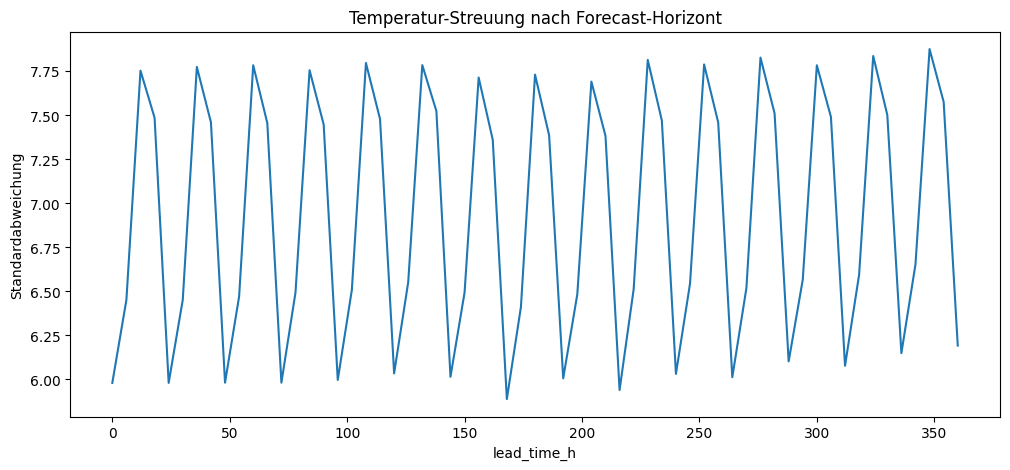

In [16]:
plt.figure(figsize=(12,5))

std_by_lead.plot()

plt.title("Temperatur-Streuung nach Forecast-Horizont")
plt.ylabel("Standardabweichung")
plt.show()

**Was der Plot zeigt:** Für jede Lead Time die Standardabweichung aller vorhergesagten Temperaturen (über alle Läufe).
Sie misst, wie stark die Vorhersagen schwanken, also wie „lebendig“ das Modell ist. Darin steckt vor allem der
Jahresgang (Winter gegen Sommer), deshalb liegt sie bei 6–7 °C. Das Zacken kommt wieder von der Tageszeit.

**Warum das für uns wichtig ist:** Wenn ein Modell bei langen Lead Times immer „mittelmäßigere“ Werte vorhersagt
(also glättet), **sinkt** die Streuung mit der Lead Time. Genau das ist unsere Hypothese für die KI-Modelle.
Allein sagt der Plot wenig; den Vergleich zwischen den Modellen machen wir in der Modellierungsphase.

## Temperatur nach Tageszeit und Monat

In [17]:
df["hour"] = (
    df["valid_time"]
      .dt.hour
)

In [18]:
hourly = (
    df.groupby("hour")
      ["temperature_2m"]
      .mean()
)

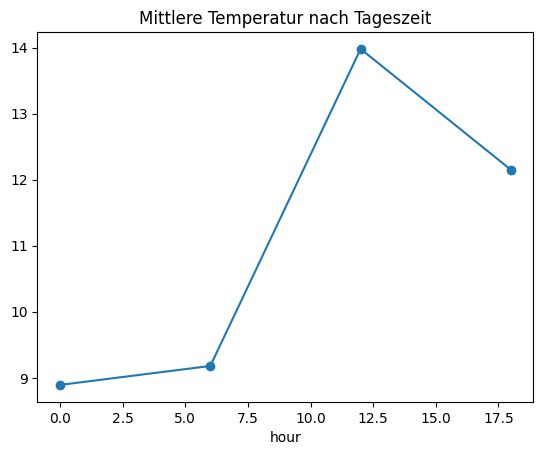

In [19]:
hourly.plot(marker="o")
plt.title("Mittlere Temperatur nach Tageszeit")
plt.show()

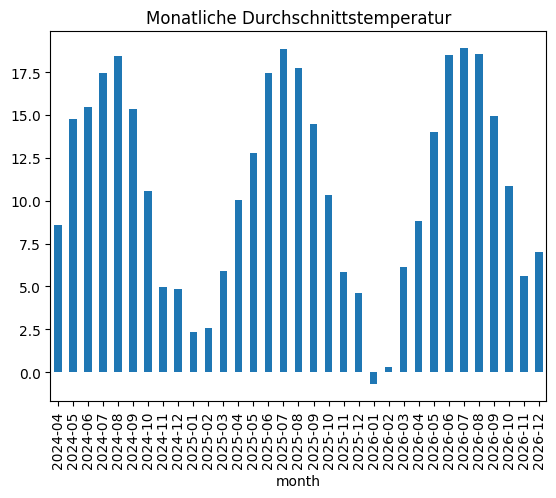

In [20]:
df["month"] = (
    df["valid_time"]
      .dt.to_period("M")
)

monthly = (
    df.groupby("month")
      ["temperature_2m"]
      .mean()
)

monthly.plot(kind="bar")
plt.title("Monatliche Durchschnittstemperatur")
plt.show()

<Axes: xlabel='hour', ylabel='lead_time_h'>

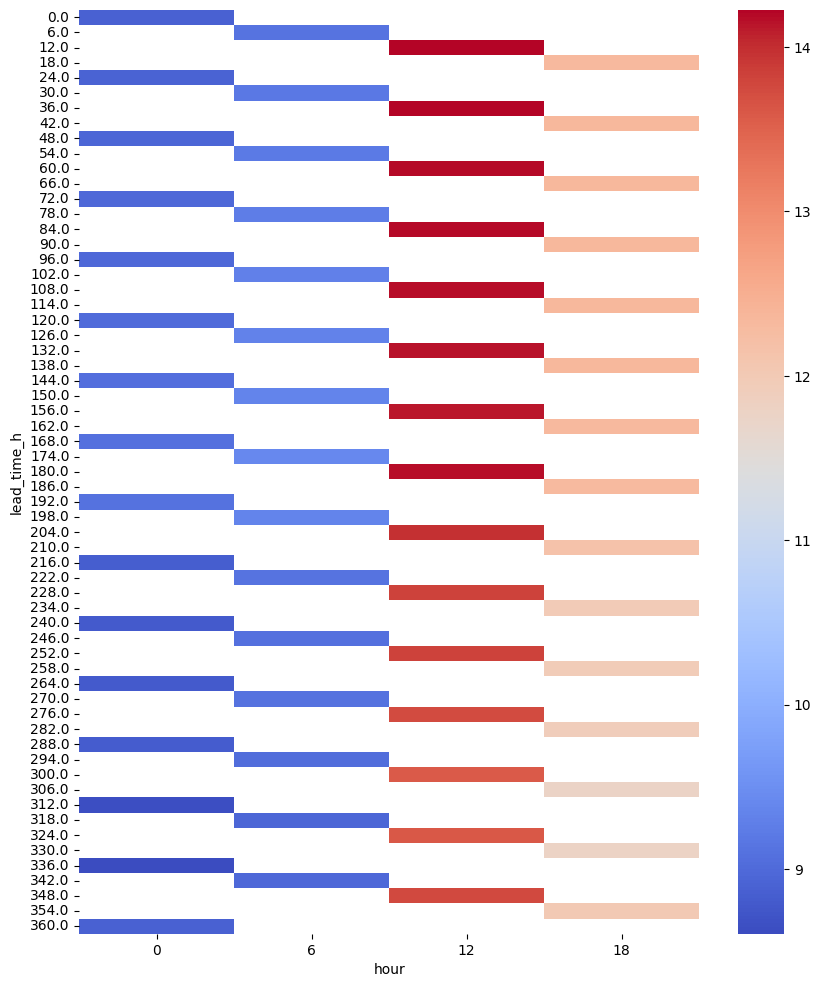

In [21]:
heatmap_data = (
    df.groupby(
        ["lead_time_h", "hour"]
    )["temperature_2m"]
    .mean()
    .unstack()
)

plt.figure(figsize=(10,12))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

## Niederschlagsvorhersage

Die Rate (mm pro Sekunde) ist der Mittelwert über die 6 Stunden **vor** dem Zeitpunkt. Mal 6 × 3600 Sekunden ergibt
die Menge in mm pro 6 h. Lead Time 0 lassen wir weg (dort gibt es keinen Wert).

In [22]:
precip = df[df["lead_time_h"] > 0].copy()

# Rate (mm/s) mal 6 Stunden in Sekunden
precip["precip_mm_6h"] = precip["precipitation_surface"] * 6 * 3600

precip["precip_mm_6h"].describe()

count    57660.000000
mean         0.566785
std          1.072026
min          0.000000
25%          0.000000
50%          0.132608
75%          0.625706
max         23.730468
Name: precip_mm_6h, dtype: float64

In [23]:
exactly_zero = (precip["precip_mm_6h"] == 0).mean()
almost_dry = (precip["precip_mm_6h"] < 0.1).mean()

print(f"Genau 0 mm: {exactly_zero:.1%}")
print(f"Unter 0,1 mm (praktisch trocken): {almost_dry:.1%}")

Genau 0 mm: 28.7%
Unter 0,1 mm (praktisch trocken): 46.4%


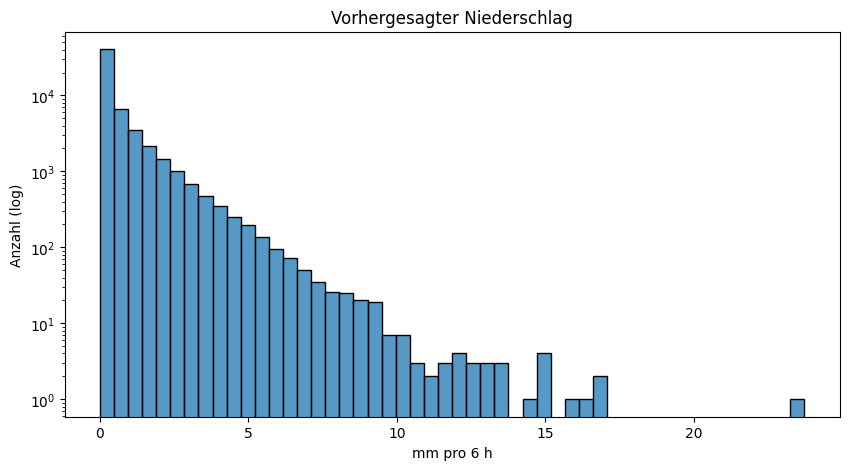

In [24]:
plt.figure(figsize=(10,5))

sns.histplot(
    precip["precip_mm_6h"],
    bins=50
)

plt.yscale("log")
plt.title("Vorhergesagter Niederschlag")
plt.xlabel("mm pro 6 h")
plt.ylabel("Anzahl (log)")
plt.show()

AIFS sagt nur in 29 % der 6-h-Fenster exakt 0 mm voraus und in 46 % weniger als 0,1 mm. Bei der DWD sind dagegen
rund 75 % der 6-h-Fenster trocken. AIFS lässt also sehr oft ein bisschen regnen („Dauernieselregen“). Das ist ein
typisches Zeichen für Glättung und passt zu unserer Hypothese. In Notebook 06 prüfen wir das direkt gegen die Messung.

## Vorhersagematrix

In [25]:
forecast_matrix = (
    df.pivot(
        index="init_time",
        columns="lead_time_h",
        values="temperature_2m"
    )
)

Text(158.22222222222223, 0.5, 'Forecast Run')

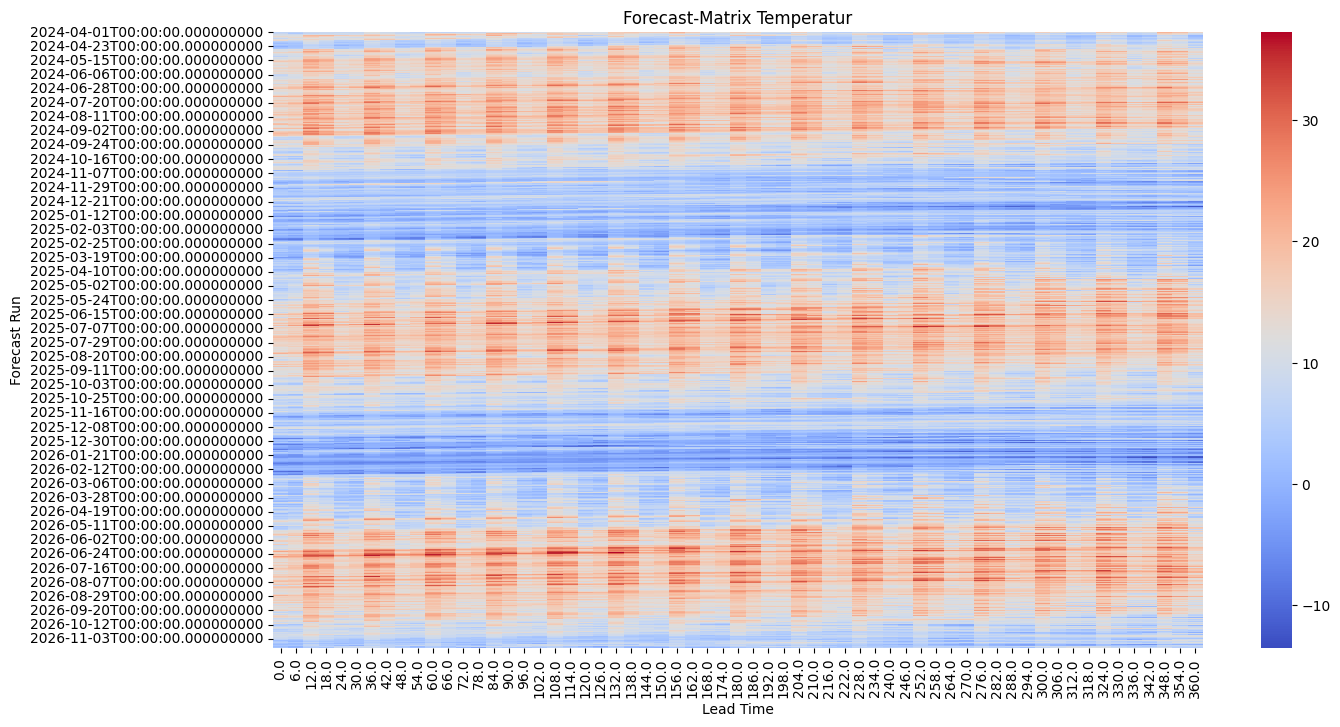

In [26]:
plt.figure(figsize=(15,8))

sns.heatmap(
    forecast_matrix,
    cmap="coolwarm"
)

plt.title("Forecast-Matrix Temperatur")
plt.xlabel("Lead Time")
plt.ylabel("Forecast Run")

**Forecast-Matrix:** Jede Zeile ist ein Lauf, jede Spalte eine Lead Time. Die waagerechten Farbbänder sind die
Jahreszeiten (Sommer rot, Winter blau), die feinen senkrechten Streifen der Tagesgang. Weiße Lücken gibt es keine.

## Erkenntnisse

- **Vollständig:** 961 Läufe (01.04.2024–17.11.2026), jeder mit allen 61 Lead Times (0–360 h).
- **Einzige Fehlwerte:** Niederschlag bei Lead Time 0, technisch bedingt.
- **Temperatur** plausibel (keine Werte außerhalb von −50…50 °C), Tages- und Jahresgang gut sichtbar.
- **Lead-Time-Plots zacken** wegen der Tageszeit (Start immer 00 UTC). Später nur gleiche Tageszeiten vergleichen.
- **Niederschlag** liegt als Rate vor und muss in mm pro 6 h umgerechnet werden. AIFS sagt sehr oft kleine Mengen
  voraus. Erste Hypothese: Das KI-Modell „verschmiert“ Niederschlag zu häufigem Niesel.
- **Modellversionen:** AIFS wurde mehrmals aktualisiert (v1 am 25.02.2025, v1.1 am 27.08.2025, v2 am 12.05.2026).
  Ob man das im Fehler sieht, prüfen wir später.